# Session 11 — Experiments you can believe

Sessions 3 and 5 trained many small GPTs and drew conclusions from the differences between them. This session asks how much of such a difference is real. We train the Session 3 model many times with different seeds and settings, and measure the noise from training, the noise from the test set, and what happens when you compare many things and report the best.

**By the end of the session you should be able to:**

1. compare two training setups with several seeds and a paired interval, and say how many seeds a given difference needs;
2. tell noise from training apart from noise from the test set, and explain why the best of many runs, and the best of many variants, look better than they are;
3. keep a record that lets someone rerun a result, and know which differences between reruns to expect.

**To run it yourself** you need the packages from Session 3 plus scipy, `tinygpt.py`, and the token cache `cache/tokens_150000.npz` written by Session 3. Training and scoring the 70 models took about 18 minutes on our laptop GPU (the training totals are printed in sections 1 and 2). The results are cached in `cache/s11_runs.json`; with that cache the notebook runs in 151 s. On a CPU, use fewer seeds and sweep settings.

In [1]:
import os, time, json, hashlib, platform, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from scipy import stats
from aij_common import DEVICE, set_seed
from tinygpt import Config, GPT, train, window_batch
set_seed(0)
data = np.load("cache/tokens_150000.npz")                                            # written by Session 3
train_ids = torch.from_numpy(data["train"].astype(np.int16)).to(DEVICE); val_all = torch.from_numpy(data["val"].astype(np.int16)).to(DEVICE)
val_ids, test_ids = val_all[: len(val_all) // 2], val_all[len(val_all) // 2:]       # two disjoint halves: one to choose with, one to report
SIZES = {"S": (128, 4, 4), "M": (192, 6, 6)}; CTX = 256
def make(size): d, L, h = SIZES[size]; return GPT(Config(d=d, layers=L, heads=h))
PARAMS = {s: sum(p.numel() for p in make(s).parameters()) / 1e6 for s in SIZES}
@torch.no_grad()
def eval_loss(m, d, batches=40, seed=123, batch=64):
    """Mean loss on `batches` random batches of 64 windows; the seed picks which windows."""
    m.eval(); g = torch.Generator().manual_seed(seed); out = []
    for _ in range(batches):
        x, y = window_batch(d, torch.randint(0, len(d) - CTX - 1, (batch,), generator=g), CTX)
        with torch.autocast("cuda", dtype=torch.bfloat16): out.append(m(x, y)[1].item())
    m.train(); return float(np.mean(out))
WINDOWS = (16, 64, 256, 1024)                                                      # sizes of the small test sets, in windows of 256 tokens
RESULTS = "cache/s11_runs.json"; runs = json.load(open(RESULTS)) if os.path.exists(RESULTS) else {}
def one_run(key, size, lr, seed, steps=300, warmup=75, keep=False, draws=0):
    """Train one model with this seed (it sets both the initial weights and the order of the batches) and score it.
    With draws > 0 it also scores the model on `draws` small test sets of each size in WINDOWS, the same sets for every model."""
    if key in runs and not keep and (draws == 0 or "draws" in runs[key]): return runs[key]
    set_seed(seed); m = make(size).to(DEVICE); t = time.perf_counter()
    train(m, train_ids, val_ids, steps, peak_lr=lr, warmup=warmup, eval_every=steps, seed=seed)
    runs[key] = {"size": size, "lr": lr, "seed": seed, "steps": steps, "val": eval_loss(m, val_ids), "test": eval_loss(m, test_ids, batches=200, seed=7), "seconds": time.perf_counter() - t}
    if draws: runs[key]["draws"] = {str(w): [eval_loss(m, test_ids, batches=max(1, w // 64), batch=min(w, 64), seed=5000 + w + j) for j in range(draws)] for w in WINDOWS}
    json.dump(runs, open(RESULTS, "w")); return (runs[key], m) if keep else runs[key]
print(f"{len(train_ids) / 1e6:.1f}M training tokens; validation half {len(val_ids) / 1e6:.2f}M, test half {len(test_ids) / 1e6:.2f}M tokens")

37.4M training tokens; validation half 0.32M, test half 0.32M tokens


## 1. One run is an anecdote

We compare two learning rates for the 3.1M-parameter model from Session 3: A (0.0045) and B (0.006), 300 steps each. A seed fixes both the initial weights and the order of the training batches. We train each setting with 12 seeds and score every model on the same large test set.

The first cell holds the helpers: the training function from Session 3, a scoring function, and a cache so that no run is trained twice. Presenters can skip it on screen.

In [2]:
CONF = {"A": 4.5e-3, "B": 6e-3}; SEEDS = range(12); t0 = time.perf_counter()
res = pd.DataFrame([{"config": c, "seed": s, **{k: v for k, v in one_run(f"seed/{c}/{s}", "M", lr, s).items() if k in ("val", "test", "seconds")}} for c, lr in CONF.items() for s in SEEDS])
print(f"24 runs of the {PARAMS['M']:.1f}M-parameter model (300 steps each): {res.seconds.sum():.0f} s of training when not cached ({res.seconds.mean():.0f} s per run)")
display(res.pivot(index="seed", columns="config", values="test").T.round(3))
summ = res.groupby("config").test.agg(["mean", "std", "min", "max"]); display(summ.round(4))

24 runs of the 3.1M-parameter model (300 steps each): 485 s of training when not cached (20 s per run)


seed,0,1,2,3,4,5,6,7,8,9,10,11
config,,,,,,,,,,,,
A,3.023,3.033,3.007,3.002,3.012,3.001,3.021,3.026,3.006,2.993,3.012,3.003
B,3.008,2.989,2.977,2.979,2.999,2.996,2.993,2.990,2.982,2.991,3.001,2.994


,mean,std,min,max
config,,,,
A,3.0116,0.0120,2.9926,3.0332
B,2.9916,0.0091,2.9767,3.0080


B is better on average, 2.9916 against 3.0116, but the seeds overlap: A's best run (2.9926) beats most of B's runs. The spread between seeds of one setting is about 0.01, half the size of the difference we are trying to measure.

> **Pause:** you train A once and B once, with unrelated seeds. How often will A come out ahead?

B minus A, averaged over 12 seeds: -0.0200 (paired 95% bootstrap interval -0.0274 to -0.0131); spread between seeds of one config: about 0.0106
one run of each with unrelated seeds: the comparison points the wrong way in 8% of the 144 possible pairs; with the same seed for both: 0% of 12
   1 seeds per config: standard error of the paired difference about 0.0131
   3 seeds per config: standard error of the paired difference about 0.0076
   5 seeds per config: standard error of the paired difference about 0.0059
  12 seeds per config: standard error of the paired difference about 0.0038


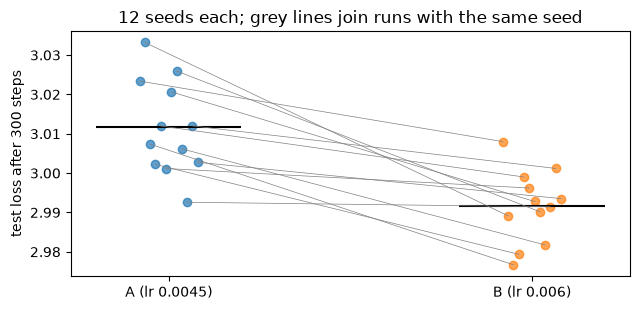

In [3]:
a, b = res[res.config == "A"].sort_values("seed").test.values, res[res.config == "B"].sort_values("seed").test.values
d = b - a; g = np.random.default_rng(0); boot = [d[g.integers(0, len(d), len(d))].mean() for _ in range(5000)]
print(f"B minus A, averaged over 12 seeds: {d.mean():+.4f} (paired 95% bootstrap interval {np.percentile(boot, 2.5):+.4f} to {np.percentile(boot, 97.5):+.4f}); spread between seeds of one config: about {summ['std'].mean():.4f}")
better = np.sign(d.mean())
flip_any = np.mean([np.sign(bj - ai) != better for ai, bj in itertools.product(a, b)])
flip_same = np.mean(np.sign(d) != better)
print(f"one run of each with unrelated seeds: the comparison points the wrong way in {flip_any:.0%} of the 144 possible pairs; with the same seed for both: {flip_same:.0%} of 12")
for n in (1, 3, 5, 12): print(f"  {n:2d} seeds per config: standard error of the paired difference about {d.std(ddof=1) / np.sqrt(n):.4f}")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for i, (c, v) in enumerate((("A (lr 0.0045)", a), ("B (lr 0.006)", b))): ax.scatter(np.full(len(v), i) + np.linspace(-0.08, 0.08, len(v)), v, alpha=0.7); ax.hlines(v.mean(), i - 0.2, i + 0.2, color="k")
for s in range(len(a)): ax.plot([0.0 + np.linspace(-0.08, 0.08, len(a))[s], 1.0 + np.linspace(-0.08, 0.08, len(b))[s]], [a[s], b[s]], color="grey", lw=0.5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["A (lr 0.0045)", "B (lr 0.006)"]); ax.set_ylabel("test loss after 300 steps"); ax.set_title("12 seeds each; grey lines join runs with the same seed"); plt.tight_layout(); plt.show()

Averaged over 12 seeds, B is lower by 0.0200, with a 95% interval from −0.0274 to −0.0131. The interval is far from 0: the difference is real.

A single run of each, with unrelated seeds, points the wrong way in 8% of the 144 possible pairs. With the same seed for both, none of the 12 pairs points the wrong way, but the grey lines in the plot cross a lot: a seed that is lucky for A is not reliably lucky for B. The standard error of the difference shows what each extra seed buys: 0.0131 with one seed per setting, 0.0076 with three, 0.0038 with twelve. A difference of 0.02 is 1.5 standard errors with one seed and more than 5 with twelve. For a smaller difference, one seed per setting gives a coin toss.

## 2. Test-set noise and the best of many

Training is one source of noise; the test set is another. A test set is a sample of text, and a different sample gives a different score. We take one trained model and score it on 20 random test sets of each size.

In [4]:
r0, m0 = one_run("seed/A/0/again", "M", CONF["A"], 0, keep=True)
spread = {b: np.std([eval_loss(m0, test_ids, batches=b, seed=s) for s in range(20)]) for b in (1, 4, 16, 64)}
for b, s in spread.items(): print(f"scoring the same model on {b:2d} batch(es) of 64 windows ({b * 64 * CTX / 1e3:,.0f}k tokens), 20 different draws: spread (std) {s:.4f}")
print(f"for comparison, the spread between training seeds was {summ['std'].mean():.4f}; same seed trained twice: test loss {runs['seed/A/0']['test']:.6f} and {r0['test']:.6f}")

scoring the same model on  1 batch(es) of 64 windows (16k tokens), 20 different draws: spread (std) 0.0417
scoring the same model on  4 batch(es) of 64 windows (66k tokens), 20 different draws: spread (std) 0.0196
scoring the same model on 16 batch(es) of 64 windows (262k tokens), 20 different draws: spread (std) 0.0109
scoring the same model on 64 batch(es) of 64 windows (1,049k tokens), 20 different draws: spread (std) 0.0049
for comparison, the spread between training seeds was 0.0106; same seed trained twice: test loss 3.023387 and 3.023387


On one batch of 64 windows (16k tokens) the score moves by 0.0417 from one test set to the next, four times the spread between training seeds. On 16 batches (262k tokens) it moves by 0.0109, as much as the seeds; on 64 batches, 0.0049. The noise halves for every fourfold increase in test data, as the square root of the size predicts.

Training itself is repeatable: the same seed trained twice gives the same test loss to every printed digit, 3.023387.

### Choosing the best of many

The usual way to tune a model is to try many settings, keep the one with the best score, and report that score. The chosen setting is partly the one that got lucky, so its score is too good. We measure how much on a fine search: 40 learning rates between 0.007 and 0.011 for the 1.1M-parameter model, each trained once with its own seed. Close settings like these are the normal situation when you tune a model that already works. Each model is scored on the large test set and on 20 small test sets of 16 to 1,024 windows; all 40 models see the same small sets, as they would with a fixed benchmark.

In [5]:
g = np.random.default_rng(42); sweep = []
for i in range(40):
    lr = float(np.exp(g.uniform(np.log(7e-3), np.log(1.1e-2))))                       # a fine search near the best learning rate, warm-up fixed at 100
    r = one_run(f"near/{i}", "S", lr, 200 + i, steps=200, warmup=100, draws=20); sweep.append({"lr": lr, "val": r["val"], "test": r["test"], "seconds": r["seconds"]})
sw = pd.DataFrame(sweep); D = {w: np.array([runs[f"near/{i}"]["draws"][str(w)] for i in range(40)]) for w in WINDOWS}   # D[w][setting, test set]
print(f"40 learning rates between 0.007 and 0.011 for the {PARAMS['S']:.1f}M-parameter model (200 steps each): {sw.seconds.sum():.0f} s of training when not cached")
print(f"large test set: best {sw.test.min():.4f}, average {sw.test.mean():.4f}, worst {sw.test.max():.4f}; spread (std) {sw.test.std():.4f}")
print(f"the same model on the validation half and on the test half: validation lower by {(sw.test - sw.val).mean():.3f} on average (from {(sw.test - sw.val).min():.3f} to {(sw.test - sw.val).max():.3f})")

40 learning rates between 0.007 and 0.011 for the 1.1M-parameter model (200 steps each): 348 s of training when not cached
large test set: best 3.3566, average 3.4019, worst 3.4429; spread (std) 0.0200
the same model on the validation half and on the test half: validation lower by 0.100 on average (from 0.090 to 0.108)


The 40 settings range from 3.3566 to 3.4429 on the large test set, with a spread of 0.0200, the same size as the seed noise in section 1.

Look also at the last line: every model scores lower on the validation half than on the test half, by 0.100 on average and at least 0.090. The two halves of the validation split are simply not equally hard. Numbers measured on different sets cannot be compared, even for the same model.

Next, we choose the best setting on each small test set and compare its gain over the average setting as it appears on that set with its gain on the large test set.

In [6]:
rows, best = [], sw.test.idxmin()
for w in WINDOWS:
    S = D[w]; pick = S.argmin(0)                                                       # on each of the 20 small test sets, the setting that looks best
    rows.append({"choose and report on": f"{w:,} windows ({w * CTX / 1e3:,.0f}k tokens)", "apparent gain over the average setting": (S.mean(0) - S[pick, np.arange(20)]).mean(),
                 "real gain (large test set)": (sw.test.mean() - sw.test.values[pick]).mean(), "picked the truly best setting": np.mean(pick == best)})
rows.append({"choose and report on": "the large test set itself", "apparent gain over the average setting": sw.test.mean() - sw.test.min(), "real gain (large test set)": sw.test.mean() - sw.test.min(), "picked the truly best setting": 1.0})
gains = pd.DataFrame(rows); display(gains.round(4))
pv = sw.val.idxmin(); print(f"chosen on the validation half instead: real gain {sw.test.mean() - sw.test[pv]:.4f}")
for w in WINDOWS:
    E = D[w] - sw.test.values[:, None]
    print(f"{w:5,} windows: a set's error shifts all 40 settings together by {E.mean(0).std():.4f} (std over the 20 sets); the part that differs between settings: {(E - E.mean(0)).std():.4f}")

,choose and report on,apparent gain over the average setting,real gain (large test set),picked the truly best setting
0,16 windows (4k tokens),0.0528,0.0403,0.65
1,64 windows (16k tokens),0.0443,0.0443,0.90
2,256 windows (66k tokens),0.0456,0.0454,1.00
3,"1,024 windows (262k tokens)",0.0453,0.0454,1.00
4,the large test set itself,0.0454,0.0454,1.00


chosen on the validation half instead: real gain 0.0454
   16 windows: a set's error shifts all 40 settings together by 0.0776 (std over the 20 sets); the part that differs between settings: 0.0114
   64 windows: a set's error shifts all 40 settings together by 0.0306 (std over the 20 sets); the part that differs between settings: 0.0054
  256 windows: a set's error shifts all 40 settings together by 0.0167 (std over the 20 sets); the part that differs between settings: 0.0028
1,024 windows: a set's error shifts all 40 settings together by 0.0102 (std over the 20 sets); the part that differs between settings: 0.0014


Luck in the test set inflates the result only on the smallest set: chosen on 16 windows, the winner appears 0.0528 better than average and is really 0.0403 better, and it is the truly best setting only 65% of the time. From 64 windows up, apparent and real gains agree. The lines below the table show why. Most of a small set's error shifts all 40 settings together (0.0306 on 64 windows), and a shift that every model shares cannot change which one wins; the part that differs between settings (0.0054) is small next to their spread of 0.0200.

So with these models the test set is not where the luck comes from. Choosing on the separate validation half picks the very same run, with the same gain of 0.0454 on the test set. But every setting was trained with a single seed, and section 1 showed that seeds alone move the loss by about 0.01.

> **Pause:** the chosen setting is 0.0454 better than the average setting on the large test set. Train the same setting again with 5 new seeds: how much of that gain will remain?

chosen setting (lr 0.0090): 3.3566 on the large test set, 0.0454 better than the average setting
the same setting trained again with 5 new seeds: 3.3918 on average (from 3.3734 to 3.4036), 0.0101 better than the average setting


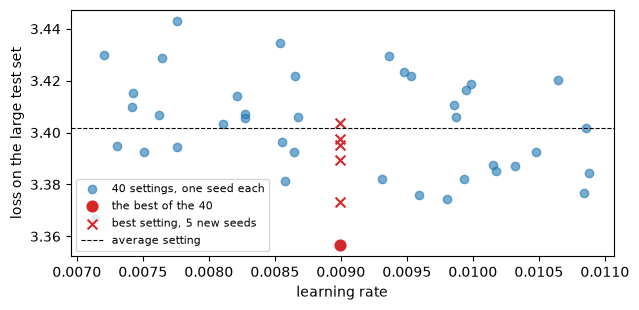

In [7]:
again = [one_run(f"near/{best}/again/{k}", "S", sw.lr[best], 300 + k, steps=200, warmup=100)["test"] for k in range(5)]   # the chosen setting, trained again with new seeds
print(f"chosen setting (lr {sw.lr[best]:.4f}): {sw.test[best]:.4f} on the large test set, {sw.test.mean() - sw.test[best]:.4f} better than the average setting")
print(f"the same setting trained again with 5 new seeds: {np.mean(again):.4f} on average (from {min(again):.4f} to {max(again):.4f}), {sw.test.mean() - np.mean(again):.4f} better than the average setting")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.scatter(sw.lr, sw.test, alpha=0.6, label="40 settings, one seed each"); ax.scatter([sw.lr[best]], [sw.test[best]], color="C3", s=60, label="the best of the 40")
ax.scatter([sw.lr[best]] * 5, again, color="C3", marker="x", s=50, label="best setting, 5 new seeds"); ax.axhline(sw.test.mean(), color="k", lw=0.8, ls="--", label="average setting")
ax.set_xlabel("learning rate"); ax.set_ylabel("loss on the large test set"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Only 0.0101 of it. The chosen learning rate (0.0090), trained again with 5 new seeds, averages 3.3918 against the 3.3566 that won the search, and all five reruns score worse than the original (3.3734 to 3.4036). In the plot the winner sits alone at the bottom and its reruns fall back into the cloud. About four-fifths of the apparent gain was a lucky seed.

This is the general rule for any choice among noisy candidates: the winner's score is biased upwards, by more when the candidates are close and the noise is large. A separate validation set protects you from luck in the test set, as above, but the luck of a single training run stays with the chosen model. To know what a setting is worth, train it again with new seeds and score it on data that played no part in the choice.

## 3. Many comparisons

A study tries 20 tweaks to a model, three seeds each, and reports the one that helps. We simulate 1,000 such studies in which no tweak does anything: every "tweak" is setting A again, with 3 of the 12 seeds from section 1, compared with a baseline made of 3 other seeds by a t-test.

In [8]:
pvals, best = [], []
for _ in range(1000):
    perm = g.permutation(a); base, tweaks = perm[:3], [g.choice(perm[3:], 3, replace=False) for _ in range(20)]   # every "tweak" is config A again, with 3 of the other 9 seeds
    ps = [stats.ttest_ind(t, base, equal_var=False).pvalue for t in tweaks]; pvals += ps
    j = int(np.argmin([t.mean() for t in tweaks])); best.append((base.mean() - tweaks[j].mean(), ps[j], min(ps)))
best = np.array(best)
print(f"tweaks that change nothing, 3 seeds each against a 3-seed baseline: p < 0.05 in {np.mean(np.array(pvals) < 0.05):.1%} of single tests")
print(f"try 20 such tweaks and report the best: at least one has p < 0.05 in {np.mean(best[:, 2] < 0.05):.0%} of studies; the best-looking tweak 'improves' the loss by {best[:, 0].mean():.4f} on average")
print(f"with the Bonferroni correction (p < 0.05 / 20) the share of studies with a false discovery is {np.mean(best[:, 2] < 0.05 / 20):.0%}")

tweaks that change nothing, 3 seeds each against a 3-seed baseline: p < 0.05 in 4.9% of single tests
try 20 such tweaks and report the best: at least one has p < 0.05 in 28% of studies; the best-looking tweak 'improves' the loss by 0.0095 on average
with the Bonferroni correction (p < 0.05 / 20) the share of studies with a false discovery is 2%


A single test gives p < 0.05 in 4.9% of cases, as it should. But a study that tries 20 tweaks finds at least one "significant" improvement in 28% of cases, and its best-looking tweak lowers the loss by 0.0095 on average, about as much as the spread between seeds. Nothing was changed. The Bonferroni correction (require p < 0.05 / 20 when you run 20 tests) brings false discoveries down to 2% of studies.

When you read a result, ask how many things were tried before it. When you report one, say how many you tried.

## 4. Records and determinism

A result is only as good as your ability to rerun it. A useful record names the exact data (by hash, since file names change), the code, the settings including the seed, the software and the hardware.

In [9]:
def sha(path): return hashlib.sha256(open(path, "rb").read()).hexdigest()[:16]
record = {"run": "seed/A/0", "config": {"size": "M", "lr": CONF["A"], "steps": 300, "warmup": 75, "batch": 64, "seed": 0}, "data": {"file": "cache/tokens_150000.npz", "sha256": sha("cache/tokens_150000.npz")},
          "code": {"tinygpt.py": sha("tinygpt.py")}, "environment": {"python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name()},
          "result": {"test_loss": runs["seed/A/0"]["test"], "test_loss_rerun": r0["test"]}}
json.dump(record, open("cache/s11_record.json", "w"), indent=1); print(json.dumps(record, indent=1))

{
 "run": "seed/A/0",
 "config": {
  "size": "M",
  "lr": 0.0045,
  "steps": 300,
  "warmup": 75,
  "batch": 64,
  "seed": 0
 },
 "data": {
  "file": "cache/tokens_150000.npz",
  "sha256": "d59e7122ccb5ccf5"
 },
 "code": {
  "tinygpt.py": "95e15c52cd75ce1d"
 },
 "environment": {
  "python": "3.12.12",
  "torch": "2.14.1+cu130",
  "cuda": "13.0",
  "gpu": "NVIDIA GeForce RTX 4070 Laptop GPU"
 },
 "result": {
  "test_loss": 3.0233868134021757,
  "test_loss_rerun": 3.0233868134021757
 }
}


The record above reran exactly: 3.0233868134021757 both times. The next cell shows the limits of that. The same matrix product on the GPU and the CPU differs by about 0.00014, because the two add the numbers in different orders and rounding depends on the order. Some GPU operations, such as a scatter-add where many threads add into the same place, have no fixed order at all.

In [10]:
torch.manual_seed(0); x = torch.randn(64, 4096, device=DEVICE); w = torch.randn(4096, 4096, device=DEVICE)
print("the same matrix product on GPU and CPU, largest difference:", ((x @ w).cpu() - x.cpu() @ w.cpu()).abs().max().item())
s1 = torch.zeros(4096, device=DEVICE).index_add_(0, torch.randint(0, 16, (4096 * 64,), generator=torch.Generator().manual_seed(1)).to(DEVICE), torch.randn(4096 * 64, generator=torch.Generator().manual_seed(2)).to(DEVICE))
s2 = torch.zeros(4096, device=DEVICE).index_add_(0, torch.randint(0, 16, (4096 * 64,), generator=torch.Generator().manual_seed(1)).to(DEVICE), torch.randn(4096 * 64, generator=torch.Generator().manual_seed(2)).to(DEVICE))
print("the same scatter-add run twice on the GPU (atomic adds, order not fixed), largest difference:", (s1 - s2).abs().max().item())

the same matrix product on GPU and CPU, largest difference: 0.00014495849609375
the same scatter-add run twice on the GPU (atomic adds, order not fixed), largest difference: 0.0011444091796875


The scatter-add run twice on the same GPU gives results that differ by about 0.001, and the difference changes from run to run. Bit-exact reruns hold on the same hardware, software and code path; across machines, expect small numerical differences, and check that conclusions survive them rather than exact digits.

## 5. Review a flawed study

A team proposes a new attention variant for small GPTs. Their report says:

- The new variant reaches a lower test loss than the baseline, a 2% improvement.
- Each model was trained once.
- The new variant was trained for twice as many steps as the baseline, which used "the standard setup".
- The variant's learning rate was chosen from fifteen values by test loss; the baseline used its default.
- Test loss was measured on one batch of 64 windows.
- The variant is the best of ten ideas the team tried; the other nine "did not help" and are not described.
- Conclusion: the variant improves language modelling.

> **Pause:** list everything that stops you believing the conclusion, and what experiment would fix each problem.

Problems the room should find, and the fixes:

- **One seed.** The spread between seeds was about 0.01 in section 1; one run each cannot tell a 2% gain from luck. Fix: several seeds per setting and an interval for the difference.
- **Unequal compute.** Twice the steps can explain the gain on its own. Fix: train both for the same steps, or report loss against compute.
- **Tuning only one side, by test loss.** The best of fifteen single runs is inflated by luck (section 2: a gain of 0.045 shrank to 0.010 on retraining). Fix: tune both with the same budget, on a validation set, confirm the winner with new seeds, and report on a test set used once.
- **A tiny test set.** One batch moves a score by 0.04 (section 2). Fix: a larger test set, and the same set for both models.
- **Ten ideas, one reported.** In section 3, 20 tweaks that changed nothing gave a "significant" result in 28% of studies. Fix: report all attempts, or correct for them.
- **A conclusion wider than the evidence.** One dataset, one model size. Fix: claim only what was tested.

## What to take away

- A single training run is an anecdote. Use several seeds, give an interval for the difference, and check how many seeds that difference needs.
- The best of many runs is too good: here four-fifths of the winner's gain was a lucky seed. Confirm a choice with new seeds, and choose on a different set from the one you report on.
- A small test set's error is mostly shared between models: the absolute number is poor, the ranking is better. Compare models on the same set.
- Trying many variants and reporting the best produces "significant" results from nothing. Count your comparisons and correct for them.
- Record data and code by hash, with every setting. Expect exact reruns on the same machine and small numerical differences elsewhere.

---

# Going deeper

Reading for after the session.

## Where the seed noise comes from

A seed fixes two things here: the initial weights and the order of the training batches. Dodge et al. (2020), *Fine-Tuning Pretrained Language Models: Weight Initializations, Data Orders, and Early Stopping*, separated the two for BERT fine-tuning and found that both contribute comparably to the variance, and that some weight initialisations do well across all the tasks they tried. To separate them in this notebook, give `train` one seed for the weights and another for the batches.

The paired interval in section 1 resamples the 12 seeds together, keeping A and B with the same seed side by side. Pairing helps when the same seed is lucky for both settings; the crossing lines in the plot show that here it is only weakly so.

## Shared and per-model test noise

Section 2 split a small test set's error into a part shared by all models and a part that differs between them. Benchmarks show the same pattern: a hard question is hard for every model. This is why a paired comparison on the same items (Session 10) is much more precise than comparing two scores each with its own interval, and why the absolute score on a small benchmark says little while differences on it can still be meaningful.

## Corrections for many comparisons

Bonferroni divides the threshold by the number of tests. It controls the chance of even one false discovery, which is strict when you test hundreds of things. Holm's method is a uniformly better version of the same idea. Benjamini and Hochberg (1995), *Controlling the False Discovery Rate: A Practical and Powerful Approach to Multiple Testing*, control instead the expected share of false discoveries among the results you report, which suits screening many candidates. None of them helps if the unsuccessful attempts are never counted.

## Determinism in PyTorch

`torch.use_deterministic_algorithms(True)` makes PyTorch use deterministic versions of operations such as the scatter-add above, or raise an error where none exists; on CUDA it also needs the environment variable `CUBLAS_WORKSPACE_CONFIG=:4096:8`. Deterministic versions are often slower. Setting `torch.backends.cudnn.benchmark = False` stops cuDNN from choosing a different algorithm from run to run. Even with all of this, a different GPU, driver or library version can change the last digits.

## What else belongs in a record

Beyond the record in section 4: the version-control commit of the code, the exact package list (this course keeps one in `_build/venv_freeze.txt`), the command that was run, and the outputs with their own hashes. Experiment trackers automate this; a JSON file per run, written by the training code itself, is enough for a course project.

## Changes from the earlier version of this session

The earlier course illustrated methodology with hand-typed example scores. This version measures each problem on models trained here. The flawed-study review is kept from the earlier course, rewritten so that each problem points at a number measured in this session.